# 17 · ResNet: 입력과 기울기가 두 길로 흐르는 블록

**이번 질문:** 이미 쓸 만한 특징을 얻었는데 층을 더 쌓을 때마다 처음부터 다시 바꿔야 할까요? 입력을 그대로 보내는 길과 작은 수정을 배우는 길을 함께 두면 무엇이 달라질까요?

과일 사진에서 얻은 두 특징을 손으로 더하는 예제에서 출발해, 고정 MNIST 숫자 7의 특징과 작은 분류 CNN으로 이어갑니다. **잔차 연결의 수식·미분·실험**을 배우는 축소 모델이며, 원 논문의 ResNet-18을 복제하거나 성능을 재현하는 노트북은 아닙니다.

- 준비물: [00](../00_기초/00_math_to_numpy.ipynb)의 shape·행렬 곱, [01](../00_기초/01_gradients_and_learning.ipynb)의 중심차분, [02](../00_기초/02_probability_and_losses.ipynb)의 softmax·CE, [04](../00_기초/04_optimizers.ipynb)의 Adam, [05](../01_아키텍처/05_cnn.ipynb)의 합성곱, [13](../02_연결/13_autodiff.ipynb)의 경로별 미분 합, [15](../02_연결/15_experiments_evaluation.ipynb)의 분할·반복 비교입니다.
- 읽는 순서: 두 경로의 덧셈 → 작은 블록의 전체 미분 → 모양이 달라지는 투영 → 깊이 진단 → 실제 MNIST 학습입니다.
- 다음 연결: [16 정규화 층](16_normalization.ipynb)에서 정규화와 잔차의 역할을 따로 보고, [18 U-Net](18_unet.ipynb)에서 덧셈 스킵과 채널 이어붙이기를 비교합니다. 이 노트북은 두 파일을 실행하거나 import하지 않습니다.

### 읽는 법

| 표시 | 뜻 | 읽는 방법 |
|---|---|---|
| 🔑 핵심 | 수식·구조·구현 | 코드를 가리고 shape와 경로를 다시 씁니다 |
| 🔍 확인 | 그림·검산·실험 | 주장과 출력 숫자를 비교합니다 |
| 📎 참고 | 환경·경계·보충 | 필요한 자리에서 돌아옵니다 |
| ✏️ 연습 | 핵심 한두 줄 | 손계산 뒤 검사하고 정답을 펼칩니다 |

**이 노트북에서 반드시 가져갈 세 가지**

1. $y=x+F(x)$의 기울기는 두 경로의 **합**입니다. 항등 경로가 있다고 전체 기울기가 항상 보존되는 것은 아닙니다.
2. 더하기 전 두 텐서의 shape가 같아야 합니다. 채널·해상도가 달라지면 $P(x)$라는 투영 경로도 학습하고 미분합니다.
3. 아키텍처, 분류 손실, optimizer와 평가 조건을 나누어 적습니다. 작은 대조 실험의 결과를 모든 ResNet의 성능 보장으로 읽지 않습니다.

| 기호 | shape | 의미 |
|---|---|---|
| $X,Y,G$ | $(N,D)$ 또는 $(N,C,H,W)$ | 입력, 블록 출력, 출력에 대한 손실 기울기 |
| $W_1,W_2$ | $(D,M),(M,D)$ | 2절 완전 연결 블록의 두 가중치 |
| $K_1,K_2$ | $(C_{out},C_{in},3,3),(C_{out},C_{out},3,3)$ | 3절 합성곱 커널 |
| $K_s$ | $(C_{out},C_{in},1,1)$ | 투영 스킵의 커널 |
| $Z,T$ | $(N,10),(N,)$ | 열이 클래스인 분류 점수, 정답 숫자 번호 |

[글 규칙](../../docs/WRITING.md) · [그림 설계](../../docs/DESIGN.md) · [그림 보조 코드](../../src/utils/resnet_plots.py)

In [1]:
# 준비 셀: 경로·배열·공통 검사·그림 도구를 불러옵니다.
import sys
from pathlib import Path
from time import perf_counter
import numpy as np
project_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src.data.mnist import load_mnist, load_examples
from src.utils import setup_plots, run_check
from src.utils.resnet_plots import (
    plot_two_paths, plot_dense_block, plot_projection, plot_depth_flow,
    plot_depth_statistics, plot_classifier_flow, plot_training_comparison,
    plot_test_predictions,
)
setup_plots()
print('NumPy', np.__version__, '· 모든 모델·미분·학습 계산은 본문에 있습니다.')

NumPy 2.4.6 · 모든 모델·미분·학습 계산은 본문에 있습니다.


📎 **실행과 모델의 범위**

NumPy·Matplotlib만으로 계산하며 커널에는 Jupyter가 필요합니다. MNIST 파일이 없으면 첫 예시 로더가 내려받습니다. 학습용 CNN은 28×28 화소를 고정 2×2 평균으로 14×14로 줄여 실행 시간을 낮춥니다. 이 변환에는 데이터에서 맞추는 통계가 없습니다. 작은 행렬에서는 커널 시작 전 `OPENBLAS_NUM_THREADS=1`, `OMP_NUM_THREADS=1`이 스레드 비용을 줄일 수 있습니다.

원래 ResNet에는 ReLU와 정규화가 들어가지만, 여기서는 두 경로의 미분을 분리해 관찰하려 **tanh·합 뒤 항등 함수·정규화 생략**을 씁니다. 따라서 16의 배치 통계와 train/eval 차이는 이 실험에 섞이지 않습니다. 깊은 실전 ResNet의 설정을 추천하는 예제가 아닙니다. [원 ResNet 논문](https://arxiv.org/abs/1512.03385)과 [항등 경로 연구](https://arxiv.org/abs/1603.05027)는 잔차 구조와 활성화 위치를 구분하는 참고 자료입니다.

> **용어** · **잔차(residual)**는 기준값에 더할 수정량입니다. **스킵 연결(skip connection)**은 일부 층을 건너 입력을 전달하는 경로입니다. 여기서는 $F(x)$가 수정량, $x$ 또는 $P(x)$가 스킵 경로입니다.
>
> **코드** · `@`는 행렬 곱, `*`는 같은 위치끼리의 곱입니다. `axis=0`은 표본 축을 합칩니다. `[:, None]`은 길이 1인 축을 추가합니다. `_`는 받아 놓고 사용하지 않는 반환값입니다. `np.stack`은 같은 모양의 배열을 새 축으로 쌓습니다.

## 🔑 1. 원래 특징에 수정량을 더합니다

**이 절에서 가져갈 것:** $y=x+F(x)$를 손계산·반복문·벡터화로 맞추고, 입력 기울기의 두 항을 설명합니다.

과일 사진에서 크기와 붉기라는 두 특징을 $x=(2,-1)$로 얻었다고 합시다. 새 층이 $F(x)=(0.5,0.25)$만큼 수정하면 결과는 $(2.5,-0.75)$입니다. 새 층은 특징 전체를 다시 만드는 대신 입력에 더할 변화를 나타냅니다.

$$Y=X+F(X),\qquad J_y=I+J_F,\qquad \nabla_x L=g+J_F^Tg.$$

마지막 식은 **표본 하나의 열벡터**로 읽습니다. $g=\partial L/\partial y$가 입력을 그대로 지난 항과, 수정 경로를 거친 항을 합합니다. 아래에서는 $F(X)=XW$, 행으로 쌓은 $X$를 쓰므로 코드의 역전파는 $dX=G+GW^T$입니다.

$$X=\begin{bmatrix}2&-1\end{bmatrix},\quad W=\begin{bmatrix}0.25&0\\0&-0.25\end{bmatrix},\quad
G=\begin{bmatrix}1&2\end{bmatrix},\quad dX=\begin{bmatrix}1.25&1.5\end{bmatrix}.$$

> **용어** · **항등(identity) 함수**는 입력을 그대로 내보냅니다. **야코비안(Jacobian) $J_F$**는 출력마다 입력에 대한 도함수를 모은 행렬입니다. **역전파의 상류 기울기 $G$**는 이 블록보다 뒤에서 이미 계산해 보내 준 $\partial L/\partial Y$입니다.

In [2]:
hand_x = np.array([[2., -1.]])
hand_w = np.diag([.25, -.25])
hand_f = hand_x @ hand_w
hand_y = hand_x + hand_f
hand_g = np.array([[1., 2.]])
hand_branch_dx = hand_g @ hand_w.T
hand_dx = hand_g + hand_branch_dx

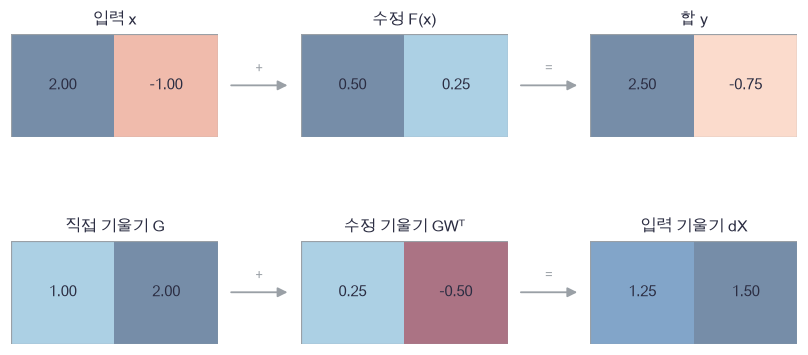

In [3]:
plot_two_paths(hand_x, hand_f, hand_y, hand_g, hand_branch_dx, hand_dx)

🔍 **그림 확인**

위에서는 두 값이 더해지고 아래에서는 두 기울기가 더해집니다. 수정 경로의 두 번째 기여가 음수이므로 스킵 기울기의 일부를 상쇄합니다. 덧셈이 있다고 두 항의 부호나 크기가 정해지는 것은 아닙니다.

$F(x)=0$이면 **합 뒤에 아무 활성화가 없을 때** $y=x$입니다. 반면 $y=\mathrm{ReLU}(x+F(x))$이면 음수 입력은 0이 되어 항등 함수가 아닙니다. 원래의 post-activation 블록과 이 노트북의 블록을 구별해야 합니다.

> **용어** · **ReLU**는 $\max(0,u)$입니다. 0에서는 미분이 매끄럽지 않으므로 뒤의 수치미분은 매끄러운 tanh 블록으로 합니다. **post-activation**은 경로를 더한 뒤 활성화 함수를 놓는 방식입니다.

In [4]:
def linear_residual_loops(x, weight):
    """표본·출력·입력 축을 직접 합합니다. x:(N,D), weight:(D,D) → y:(N,D)."""
    y = x.copy()
    for n in range(x.shape[0]):
        for j in range(x.shape[1]):
            for i in range(x.shape[1]):
                y[n, j] += x[n, i]*weight[i, j]
    return y

In [5]:
# 쓰는 것: hand_x, hand_w, hand_y, hand_g, hand_dx (1절 손계산)
np.testing.assert_allclose(linear_residual_loops(hand_x, hand_w), [[2.5, -.75]])  # 검산: 손계산 두 좌표와 같습니다.
np.testing.assert_allclose(hand_y, linear_residual_loops(hand_x, hand_w))  # 검산: 벡터화와 반복문이 같습니다.
np.testing.assert_allclose(hand_dx, [[1.25, 1.5]])  # 검산: 직접 기여와 수정 기여를 더합니다.
zero_branch = np.zeros_like(hand_x)
np.testing.assert_array_equal(hand_x + zero_branch, hand_x)  # 검산: 합 뒤 활성화가 없으면 항등입니다.
np.testing.assert_array_equal(np.maximum(hand_x + zero_branch, 0), [[2., 0.]])  # 검산: post-ReLU는 음수 좌표를 지웁니다.
print('두 경로 손계산·반복문·벡터화 및 zero-residual 경계 확인')

두 경로 손계산·반복문·벡터화 및 zero-residual 경계 확인


### ✏️ 연습 1 · 입력 기울기는 두 길의 합

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

선형 수정 $F(X)=XW$에서 상류 기울기 `g`와 `weight`를 받습니다. 입력 기울기 한 줄을 채우세요.

In [6]:
def exercise_two_paths(g, weight):
    """행벡터 배치에서 직접 기울기와 수정 경로 기울기를 더합니다."""
    raise NotImplementedError
    return dx

In [7]:
def check_two_paths(candidate):
    """음수 수정 기울기가 직접 경로 일부를 상쇄하는 손계산입니다."""
    actual = candidate(np.array([[2., 3.]]), np.diag([.5, -1.]))
    np.testing.assert_allclose(actual, [[3., 0.]])  # 검산: 2+1=3이고 3-3=0입니다.
run_check(check_two_paths, exercise_two_paths)

☐ exercise_two_paths: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dx = g + g @ weight.T
```

</details>

## 🔑 2. 두 층 블록을 끝까지 미분합니다

**이 절에서 가져갈 것:** 비선형 수정 경로의 모든 가중치·편향과 입력을 검산합니다.

숫자 7의 왼쪽과 오른쪽 잉크 평균을 특징 두 개로 씁니다. 세 은닉 값으로 조합한 뒤 다시 두 특징의 수정량을 만들어 더합니다. 그림 속 작은 벡터는 전체 그림을 압축한 **설명용 특징**이며 마지막 분류기의 입력은 화소 배열입니다.

$$A=\tanh(XW_1+b_1),\qquad F=AW_2+b_2,\qquad Y=X+\alpha F.$$

$X,Y$는 $(N,D)$, $A$는 $(N,M)$, $W_1$은 $(D,M)$, $W_2$는 $(M,D)$입니다. $\alpha$는 학습하지 않는 수정량 배율이며 이 절에서는 1입니다. 비교용 plain 블록은 같은 $F$로 $Y=\alpha F$만 출력합니다.

$$G_F=\alpha G,\quad dW_2=A^TG_F,\quad db_2=\sum_n(G_F)_n,$$
$$G_U=(G_FW_2^T)\odot(1-A^2),\quad dW_1=X^TG_U,\quad db_1=\sum_n(G_U)_n,\quad dX=G+G_UW_1^T.$$

plain 블록에서는 마지막 식의 직접 항 $G$만 빠집니다. 가중치를 갱신하기 전에 두 경로를 모두 미분해야 합니다.

> **용어** · **tanh**는 출력을 $(-1,1)$로 누르며 도함수는 $1-\tanh^2(u)$입니다. **plain 블록**은 같은 층을 순서대로 통과하되 더하는 스킵 경로가 없는 비교 구조입니다. **MNIST**는 숫자 0–9를 담은 28×28 손글씨 그림 자료입니다. **화소(pixel)** 하나는 그림 한 칸의 잉크 양입니다.

In [8]:
mnist_examples, mnist_example_labels = load_examples(download=True)
example_seven = mnist_examples[7]
dense_x = np.array([[example_seven[:, :14].mean(), example_seven[:, 14:].mean()]])
dense_params = {
    'W1': np.array([[.5, -.2, .3], [.1, .4, -.2]]), 'b1': np.array([.1, -.1, .2]),
    'W2': np.array([[.2, -.1], [.1, .3], [-.2, .1]]), 'b2': np.array([.01, -.02]),
}
dense_a = np.tanh(dense_x @ dense_params['W1'] + dense_params['b1'])
dense_f = dense_a @ dense_params['W2'] + dense_params['b2']
dense_y = dense_x + dense_f

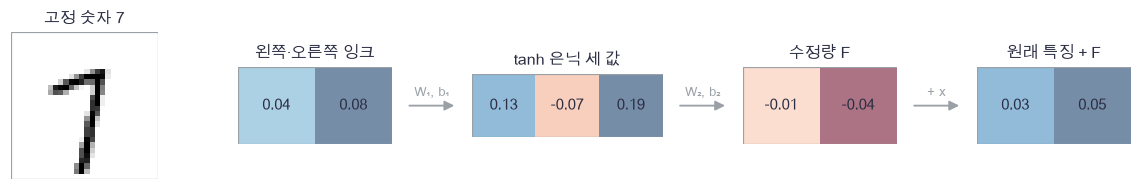

In [9]:
plot_dense_block(example_seven, dense_x, dense_a, dense_f, dense_y)

🔍 **그림 확인**

세 은닉 값은 수정량 두 개를 만드는 중간 재료입니다. 마지막 두 칸은 원래 특징에 수정량을 더한 결과입니다. 고정한 가중치의 산술을 보인 그림이며 좋은 수정량을 학습했다는 결과는 아닙니다.

아래에서는 forward의 중간 배열을 cache에 저장해 backward가 다시 씁니다. 독립 검산은 임의의 $G$를 고정한 스칼라 $s=\sum_{n,d}Y_{nd}G_{nd}$를 미분합니다. 따라서 검산할 backward 입력은 정확히 그 $G$입니다.

> **코드** · `params['W1']`은 이름으로 가중치를 찾는 사전입니다. `params.items()`는 이름과 배열을 함께 꺼냅니다. `np.ndindex(shape)`는 모든 원소의 인덱스를 방문합니다. `try/finally`는 계산 중 오류가 나도 바꾼 값을 반드시 원래대로 돌립니다.

In [10]:
def dense_block_forward(x, params, residual=True, scale=1.0):
    """두 선형 층 사이 tanh와 선택적 잔차 합. x:(N,D) → y:(N,D), cache."""
    hidden = np.tanh(x @ params["W1"] + params["b1"])
    branch = hidden @ params["W2"] + params["b2"]
    y = scale * branch
    if residual:
        y = y + x
    return y, (x, hidden, residual, scale)

In [11]:
def dense_block_backward(dy, cache, params):
    """g와 J_F의 경로를 합합니다. dy:(N,D) → dx:(N,D), 이름별 파라미터 기울기."""
    x, hidden, residual, scale = cache
    dbranch = scale * dy
    dhidden = dbranch @ params["W2"].T
    du = dhidden * (1 - hidden**2)
    gradients = {"W2": hidden.T @ dbranch, "b2": dbranch.sum(axis=0),
                 "W1": x.T @ du, "b1": du.sum(axis=0)}
    dx = du @ params["W1"].T
    if residual:
        dx = dx + dy
    return dx, gradients

In [12]:
def central_difference(objective, values, step=1e-6):
    """스칼라 함수의 모든 배열 원소를 양쪽으로 흔들고 항상 원래 값으로 돌립니다."""
    gradient = np.empty_like(values)
    for index in np.ndindex(values.shape):
        original = values[index]
        try:
            values[index] = original + step
            plus = objective()
            values[index] = original - step
            minus = objective()
        finally:
            values[index] = original
        gradient[index] = (plus-minus) / (2*step)
    return gradient

In [13]:
# 쓰는 것: dense_x, dense_params, dense_y (2절 개념 계산)
dense_actual, dense_cache = dense_block_forward(dense_x, dense_params)
np.testing.assert_allclose(dense_actual, dense_y)  # 검산: 핵심 구현이 개념 그림의 계산과 같습니다.
dense_upstream = np.array([[.7, -1.2]])
dense_dx, dense_gradients = dense_block_backward(dense_upstream, dense_cache, dense_params)

In [14]:
# 쓰는 것: dense_block_forward (2절), dense_x, dense_params, dense_upstream (2절 검산)
def dense_probe():
    """고정 상류 기울기와 출력의 내적으로 스칼라 검산 함수를 만듭니다."""
    output, _ = dense_block_forward(dense_x, dense_params)
    return float(np.sum(output*dense_upstream))

In [15]:
# 쓰는 것: central_difference, dense_probe, dense_gradients, dense_dx, dense_x, dense_params, dense_block_forward, dense_block_backward (2절)
for name, values in dense_params.items():
    numeric = central_difference(dense_probe, values)
    np.testing.assert_allclose(dense_gradients[name], numeric, rtol=1e-5, atol=1e-9)  # 검산: 각 파라미터의 모든 원소를 대조합니다.
numeric_dense_x = central_difference(dense_probe, dense_x)
np.testing.assert_allclose(dense_dx, numeric_dense_x, rtol=1e-5, atol=1e-9)  # 검산: 입력에는 두 경로를 모두 합쳤습니다.
plain_y, plain_cache = dense_block_forward(dense_x, dense_params, residual=False)
plain_dx, _ = dense_block_backward(dense_upstream, plain_cache, dense_params)
np.testing.assert_allclose(dense_dx-plain_dx, dense_upstream)  # 검산: 이 한 블록의 같은 상류 기울기에서는 차이가 직접 항입니다.
print('2층 블록의 네 파라미터 배열과 입력 전체 중심차분 통과')

2층 블록의 네 파라미터 배열과 입력 전체 중심차분 통과


### ✏️ 연습 2 · 은닉 활성화를 거슬러 올라가기

`a`는 tanh 출력, `upstream`은 그 출력에 대한 기울기입니다. tanh 입력 기울기 한 줄을 채우세요.

In [16]:
def exercise_tanh_route(a, upstream):
    """수정 경로 안의 tanh 도함수를 곱합니다."""
    raise NotImplementedError
    return du

In [17]:
def check_tanh_route(candidate):
    """0·0.5에서의 tanh 도함수 1·0.75를 확인합니다."""
    result = candidate(np.array([[0., .5]]), np.array([[3., -4.]]))
    np.testing.assert_allclose(result, [[3., -3.]])  # 검산: 3×1과 -4×.75입니다.
run_check(check_tanh_route, exercise_tanh_route)

☐ exercise_tanh_route: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
du = upstream * (1-a**2)
```

</details>

## 🔑 3. 채널과 해상도가 바뀌면 스킵도 바꿉니다

**이 절에서 가져갈 것:** 3×3 주경로와 1×1 투영의 출력 shape를 맞추고 입력 미분을 합합니다.

숫자 그림의 공간 크기를 절반쯤 줄이고 특징 채널은 늘리고 싶습니다. 원래 입력을 그대로 더하면 높이·너비·채널이 맞지 않습니다. 스킵에도 학습 가능한 1×1 합성곱을 놓아 같은 shape로 바꿉니다.

$$A=\tanh(\operatorname{Conv}_{3\times3,s,p=1}(X;K_1,b_1)),\quad
F=\operatorname{Conv}_{3\times3,1,1}(A;K_2,b_2),$$
$$P(X)=\operatorname{Conv}_{1\times1,s,0}(X;K_s,b_s),\qquad Y=P(X)+\alpha F(X).$$

입력은 $(N,C_{in},H,W)$이며 출력 높이는
$$H_o=\left\lfloor\frac{H+2p-k}{s}\right\rfloor+1,$$
너비도 같은 식입니다. $k=3,p=1,s=2$인 주경로와 $k=1,p=0,s=2$인 투영은 모두 $H_o=\lceil H/2\rceil$입니다. 홀수 크기에서도 일치하지만 $P$는 더 이상 항등 함수가 아닙니다.

$$dX=J_P^TG+\alpha J_F^TG.$$

두 경로가 같은 입력을 사용했으므로 각각 구한 입력 기여를 **더합니다**. 덧셈을 한 경로의 기울기로 덮어쓰면 안 됩니다.

> **용어** · **채널(channel)**은 한 위치에서 보유한 특징의 종류입니다. **stride $s$**는 창이 움직이는 간격, **padding $p$**는 가장자리에 붙이는 0의 폭입니다. **투영(projection) 스킵**은 여기서 shape를 맞추는 학습 가능한 선형 변환이며, 직교 투영이라는 뜻은 아닙니다. 1×1 커널은 공간 이웃을 섞지 않고 같은 위치의 채널을 섞습니다.

In [18]:
# 쓰는 것: example_seven (2절 고정 MNIST 예시)
projection_x = example_seven[::4, ::4][None, None]  # (1,1,7,7)
projection_sampled = projection_x[:, :, ::2, ::2]
projection_hidden = np.tanh(projection_sampled * np.array([.3, .6])[None, :, None, None])
projection_branch = .2 * projection_hidden
projection_skip = projection_sampled * np.array([1., -.5])[None, :, None, None]
projection_y = projection_skip + projection_branch
projection_shapes = ['1×7×7', '2×4×4', '2×4×4', '2×4×4']

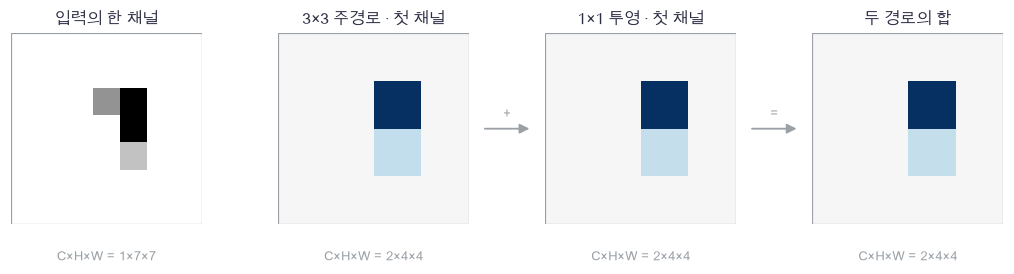

In [19]:
plot_projection(projection_x[0, 0], projection_branch[0, 0], projection_skip[0, 0], projection_y[0, 0], projection_shapes)

🔍 **그림 확인**

그림은 출력의 첫 채널만 보여 주고 shape에는 두 채널을 모두 셉니다. 주경로의 3×3 커널에서 가운데 원소만 남긴 예라 직접 배열 연산으로 계산했습니다. 같은 위치의 두 경로를 더할 수 있고, 원본 7×7 입력을 4×4 출력에 바로 더할 수는 없습니다.

05의 합성곱을 아래에 다시 적습니다. 실제 구현은 커널을 뒤집지 않는 신경망의 합성곱, 즉 교차상관입니다. 입력 창을 행으로 펴면 $V=X_{col}K_{flat}^T+b$가 됩니다. 따라서 $dK=G_{row}^TX_{col}$, $dX_{col}=G_{row}K_{flat}$입니다. 겹치는 창의 입력 미분은 원래 화소에 누적합니다.

> **코드** · `np.pad`는 가장자리를 채웁니다. `sliding_window_view(..., axis=(2,3))`는 높이·너비의 모든 창을 `(N,C,Ho,Wo,k,k)`로 보여 줍니다. `::stride`는 그 간격으로 위치를 고릅니다. `transpose`는 축 순서를, `reshape`는 원소 순서를 유지하며 모양을 바꿉니다. `a += b`는 같은 칸에 기여를 누적합니다. `None`은 투영 cache가 없음을 표시합니다.

In [20]:
def conv_forward(x, weight, bias, stride=1, padding=0):
    """NCHW 합성곱을 창 행렬로 계산합니다. W:(O,C,K,K) → y:(N,O,Ho,Wo), cache."""
    n, channels, height, width = x.shape
    out_channels, _, kh, kw = weight.shape
    padded = np.pad(x, ((0, 0), (0, 0), (padding, padding), (padding, padding)))
    windows = np.lib.stride_tricks.sliding_window_view(padded, (kh, kw), axis=(2, 3))
    windows = windows[:, :, ::stride, ::stride]
    ho, wo = windows.shape[2:4]
    columns = windows.transpose(0, 2, 3, 1, 4, 5).reshape(n*ho*wo, -1)
    values = columns @ weight.reshape(out_channels, -1).T + bias
    output = values.reshape(n, ho, wo, out_channels).transpose(0, 3, 1, 2)
    cache = (x.shape, weight, stride, padding, columns, ho, wo)
    return output, cache

In [21]:
def conv_backward(dy, cache):
    """창별 입력 기여를 겹치는 위치에 더합니다. dy:(N,O,Ho,Wo) → dx,dW,db."""
    # 1. 출력 공간을 행으로 펴면 가중치 미분은 하나의 행렬 곱입니다.
    shape, weight, stride, padding, columns, ho, wo = cache
    n, channels, height, width = shape
    out_channels, _, kh, kw = weight.shape
    rows = dy.transpose(0, 2, 3, 1).reshape(n*ho*wo, out_channels)
    dweight = (rows.T @ columns).reshape(weight.shape)
    dbias = rows.sum(axis=0)
    dcolumns = rows @ weight.reshape(out_channels, -1)
    patches = dcolumns.reshape(n, ho, wo, channels, kh, kw).transpose(0, 3, 1, 2, 4, 5)
    # 2. 같은 입력 화소를 여러 창이 썼으므로 대입이 아니라 누적합니다.
    padded_dx = np.zeros((n, channels, height+2*padding, width+2*padding))
    for u in range(kh):
        for v in range(kw):
            padded_dx[:, :, u:u+ho*stride:stride, v:v+wo*stride:stride] += patches[:, :, :, :, u, v]
    dx = padded_dx[:, :, padding:padding+height, padding:padding+width]
    return dx, dweight, dbias

In [22]:
def init_conv_block(in_channels, out_channels, stride, rng):
    """3×3 주경로와 필요할 때만 1×1 투영 가중치를 만듭니다."""
    params = {
        "W1": rng.normal(size=(out_channels, in_channels, 3, 3)) / np.sqrt(9*in_channels),
        "b1": np.zeros(out_channels),
        "W2": rng.normal(size=(out_channels, out_channels, 3, 3)) / np.sqrt(9*out_channels),
        "b2": np.zeros(out_channels),
    }
    if in_channels != out_channels or stride != 1:
        params["Ws"] = rng.normal(size=(out_channels, in_channels, 1, 1)) / np.sqrt(in_channels)
        params["bs"] = np.zeros(out_channels)
    return params

In [23]:
# 쓰는 것: conv_forward (3절 합성곱)
def conv_block_forward(x, params, stride=1, residual=True, scale=1.0):
    """tanh를 사이에 둔 두 3×3 conv와 skip을 합하며 합 뒤 활성화는 없습니다."""
    first, first_cache = conv_forward(x, params["W1"], params["b1"], stride, 1)
    hidden = np.tanh(first)
    branch, second_cache = conv_forward(hidden, params["W2"], params["b2"], 1, 1)
    y = scale * branch
    skip_cache = None
    if residual:
        skip = x
        if "Ws" in params:
            skip, skip_cache = conv_forward(x, params["Ws"], params["bs"], stride, 0)
        assert skip.shape == branch.shape, "두 경로의 N,C,H,W가 같아야 더할 수 있습니다"
        y = y + skip
    return y, (hidden, first_cache, second_cache, skip_cache, residual, scale)

In [24]:
# 쓰는 것: conv_backward (3절 합성곱 미분)
def conv_block_backward(dy, cache, params):
    """주경로·투영 경로를 따로 거슬러 올라간 뒤 입력 기울기를 합합니다."""
    hidden, first_cache, second_cache, skip_cache, residual, scale = cache
    dhidden, dw2, db2 = conv_backward(scale*dy, second_cache)
    dfirst = dhidden * (1 - hidden**2)
    dx, dw1, db1 = conv_backward(dfirst, first_cache)
    gradients = {"W1": dw1, "b1": db1, "W2": dw2, "b2": db2}
    if residual:
        dskip = dy
        if skip_cache is not None:
            dskip, gradients["Ws"], gradients["bs"] = conv_backward(dy, skip_cache)
        dx = dx + dskip
    return dx, gradients

In [25]:
def conv_loops(x, weight, bias, stride=1, padding=0):
    """작은 검산용 합성곱: 출력 위치·채널·입력 창의 합을 직접 풉니다."""
    n, channels, height, width = x.shape
    out_channels, _, kh, kw = weight.shape
    ho = (height+2*padding-kh)//stride+1
    wo = (width+2*padding-kw)//stride+1
    padded = np.pad(x, ((0,0),(0,0),(padding,padding),(padding,padding)))
    output = np.zeros((n, out_channels, ho, wo))
    for sample in range(n):
        for o in range(out_channels):
            for i in range(ho):
                for j in range(wo):
                    total = bias[o]
                    for c in range(channels):
                        for u in range(kh):
                            for v in range(kw):
                                total += padded[sample,c,i*stride+u,j*stride+v]*weight[o,c,u,v]
                    output[sample,o,i,j] = total
    return output

In [26]:
# 쓰는 것: projection_x, projection_y (3절 개념 계산), conv_forward, init_conv_block (3절)
projection_params = init_conv_block(1, 2, 2, np.random.default_rng(1730))
for values in projection_params.values():
    values.fill(0.)
projection_params['W1'][:, 0, 1, 1] = [.3, .6]
projection_params['W2'][0, 0, 1, 1] = .2
projection_params['W2'][1, 1, 1, 1] = .2
projection_params['Ws'][:, 0, 0, 0] = [1., -.5]
projection_actual, _ = conv_block_forward(projection_x, projection_params, stride=2)
np.testing.assert_allclose(projection_actual, projection_y)  # 검산: 두 채널 모두 개념 그림의 직접 계산과 같습니다.
small_conv_x = np.arange(12.).reshape(1,1,3,4)/10
small_conv_w = np.array([[[[1., -1.], [.5, .25]]]])
small_conv_b = np.array([.1])
vector_conv, _ = conv_forward(small_conv_x, small_conv_w, small_conv_b, 2, 1)
np.testing.assert_allclose(vector_conv, conv_loops(small_conv_x, small_conv_w, small_conv_b, 2, 1))  # 검산: padding·stride와 경계의 합이 같습니다.
print('합성곱 반복문·창 행렬 및 투영 그림 계산 통과')

합성곱 반복문·창 행렬 및 투영 그림 계산 통과


In [27]:
# 쓰는 것: conv_block_forward, conv_block_backward, init_conv_block (3절), central_difference (2절)
def check_conv_block_all(in_channels, out_channels, stride, seed):
    """작은 홀수·짝수 공간에서 모든 커널·편향·입력 원소를 독립 중심차분합니다."""
    rng = np.random.default_rng(seed)
    x = rng.normal(0, .3, (1, in_channels, 3, 4))
    params = init_conv_block(in_channels, out_channels, stride, rng)
    y, cache = conv_block_forward(x, params, stride)
    upstream = rng.normal(size=y.shape)
    dx, gradients = conv_block_backward(upstream, cache, params)
    def objective():
        """상류 배열을 고정한 출력 내적입니다."""
        output, _ = conv_block_forward(x, params, stride)
        return float(np.sum(output*upstream))
    largest_error = 0.
    for name, values in params.items():
        numeric = central_difference(objective, values)
        np.testing.assert_allclose(gradients[name], numeric, atol=2e-8, rtol=3e-5)  # 검산: 각 커널·편향의 모든 원소가 같습니다.
        largest_error = max(largest_error, np.max(np.abs(gradients[name]-numeric)))
    numeric_x = central_difference(objective, x)
    np.testing.assert_allclose(dx, numeric_x, atol=2e-8, rtol=3e-5)  # 검산: 입력에는 주경로와 스킵 기여가 모두 있습니다.
    return y.shape, max(largest_error, np.max(np.abs(dx-numeric_x)))

In [28]:
identity_shape, identity_error = check_conv_block_all(2, 2, 1, 1731)
projected_shape, projected_error = check_conv_block_all(1, 2, 2, 1732)
print('항등 스킵:', identity_shape, '최대 절대오차', identity_error)
print('투영 스킵:', projected_shape, '최대 절대오차', projected_error)

항등 스킵: (1, 2, 3, 4) 최대 절대오차 2.9607627460848107e-10
투영 스킵: (1, 2, 2, 2) 최대 절대오차 1.1347559003560548e-10


### ✏️ 연습 3 · 홀수 크기의 출력 높이

입력 높이 `height`, 커널 `kernel`, padding `padding`, stride `stride`를 받습니다. 버림 나눗셈 `//`으로 출력 높이 한 줄을 채우세요.

In [29]:
def exercise_output_height(height, kernel, padding, stride):
    """창이 입력 안에서 놓일 수 있는 출력 위치 수를 셉니다."""
    raise NotImplementedError
    return out_height

In [30]:
def check_output_height(candidate):
    """높이 7에서 두 경로가 모두 높이 4를 만드는지 검사합니다."""
    assert candidate(7, 3, 1, 2) == 4, "3×3 주경로의 출력 높이는 4여야 합니다"
    assert candidate(7, 1, 0, 2) == 4, "1×1 투영의 출력 높이도 4여야 합니다"
run_check(check_output_height, exercise_output_height)

☐ exercise_output_height: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
out_height = (height + 2*padding - kernel)//stride + 1
```

</details>

## 🔑 4. 깊어질 때 신호와 기울기를 따로 잽니다

**이 절에서 가져갈 것:** 같은 수정 가중치로 plain·잔차 경로를 비교하고, 보존·상쇄·증폭을 구별합니다.

특징을 여러 번 손질하면서 처음의 정보를 잃을 수 있습니다. $F(x)=0.5x$인 층만 세 번 지나면 plain은 $0.5^3x$, 잔차는 $1.5^3x$가 됩니다. 전자는 작아지고 후자는 커집니다. 잔차가 있다고 값의 크기가 그대로인 것은 아닙니다.

$$x_{\ell+1}=x_\ell+F_\ell(x_\ell),\qquad
J_{0\to L}=(I+J_{F_{L-1}})\cdots(I+J_{F_0}).$$

미분할 때 각 $J_{F_\ell}$은 **그 구조의 실제 중간 입력**에서 평가합니다. 앞 블록의 출력이 달라지므로 깊은 plain 모델과 잔차 모델의 전체 기울기 차이를 단순히 $G$ 하나라고 할 수는 없습니다. 2절의 그 검산은 같은 입력·상류 기울기를 준 블록 하나에 관한 것이었습니다.

> **용어** · **활성 크기**는 중간 출력의 RMS $\sqrt{\operatorname{mean}(x^2)}$로 잽니다. **기울기 노름**은 미분 원소 제곱합의 제곱근입니다. 아래의 비율 $\|dX\|_F/\|G\|_F$는 주어진 출력 방향 $G$의 증폭 정도이며 모든 방향의 최소·최대 증폭을 보장하지 않습니다.

In [31]:
depth_steps = np.arange(4)
scalar_plain = .5**depth_steps
scalar_residual = 1.5**depth_steps
scalar_plain_gain = .5**3
scalar_residual_gain = 1.5**3

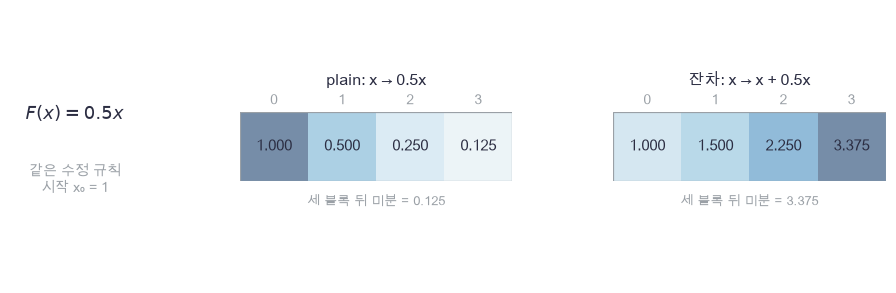

In [32]:
plot_depth_flow(depth_steps, scalar_plain, scalar_residual, scalar_plain_gain, scalar_residual_gain)

🔍 **그림 확인**

같은 수정 함수가 있어도 덧셈 스킵 유무가 다음 입력과 미분의 곱을 바꿉니다. 단순한 경우조차 두 구조 중 하나가 항상 크기를 잘 유지한다고 말할 수 없습니다. $F(x)=-x$면 잔차 전체가 0으로 상쇄되고, $F(x)=x$면 매번 두 배가 됩니다.

이제 16차원 tanh 블록을 1·2·4·8·16개 쌓습니다. 각 seed에서 같은 가중치 목록의 앞부분을 사용하고, 두 구조는 같은 입력·상류 기울기·배율 $\alpha=1$을 씁니다. 학습하기 전의 **초기화 진단**이므로 정확도 결과로 읽지 않습니다.

> **코드** · `reversed(caches)`는 뒤 블록부터 거슬러 갑니다. `zip(a,b)`는 두 목록에서 같은 위치의 원소를 묶습니다. 사전·리스트 내포는 반복문으로 만든 이름별 배열·목록을 짧게 적습니다. 여기의 평균±SD는 독립 seed 사이의 표준편차이며 평균의 표준오차가 아닙니다.

In [33]:
# 쓰는 것: dense_block_forward, dense_block_backward (2절)
def depth_measurements(x, blocks, depth, residual):
    """지정 깊이의 출력 RMS와 고정 평균출력 방향의 입력 기울기 증폭을 계산합니다."""
    h = x.copy()
    caches = []
    for params in blocks[:depth]:
        h, cache = dense_block_forward(h, params, residual=residual)
        caches.append((params, cache))
    upstream = np.ones_like(h) / h.size
    dx = upstream.copy()
    for params, cache in reversed(caches):
        dx, _ = dense_block_backward(dx, cache, params)
    return np.sqrt(np.mean(h**2)), np.linalg.norm(dx)/np.linalg.norm(upstream)

In [34]:
depths = np.array([1, 2, 4, 8, 16])
depth_seeds = [1740, 1741, 1742]
depth_results = np.empty((2, len(depth_seeds), len(depths), 2))
for r, seed in enumerate(depth_seeds):
    rng = np.random.default_rng(seed)
    x = rng.normal(0, .2, (8, 16))
    blocks = []
    for block_index in range(16):
        blocks.append({'W1': rng.normal(size=(16,16))/4, 'b1': np.zeros(16),
                       'W2': rng.normal(size=(16,16))/4, 'b2': np.zeros(16)})
    for mode, skip in enumerate([False, True]):
        for j, depth in enumerate(depths):
            depth_results[mode, r, j] = depth_measurements(x, blocks, depth, skip)
depth_means = depth_results.mean(axis=1)
depth_sds = depth_results.std(axis=1, ddof=1)

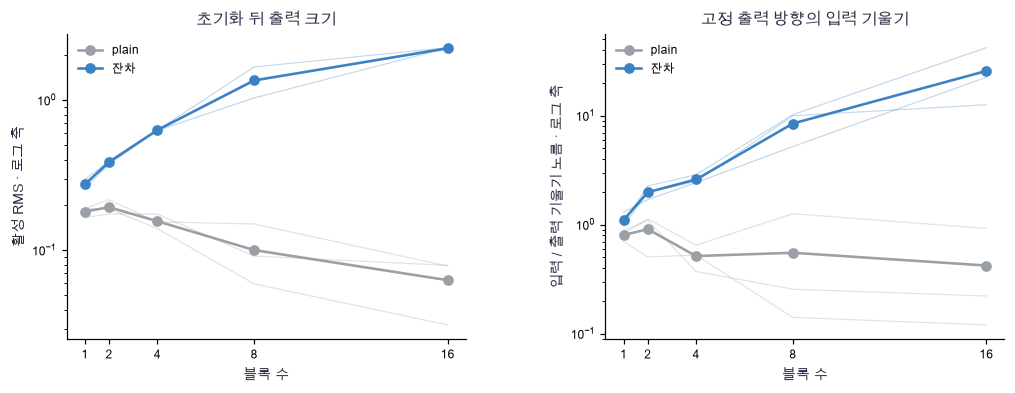

In [35]:
plot_depth_statistics(depths, depth_means, depth_results, ["plain", "잔차"])

🔍 **깊이 실험 확인**

가는 선은 각 seed의 실제 곡선, 굵은 선은 세 seed의 평균입니다. 두 그림의 세로축은 로그 척도입니다. 같은 배율의 변화가 같은 거리로 보입니다. 잔차 경로에서 입력 기울기가 더 남더라도 활성 크기가 커지는지 함께 확인합니다. 이 세 seed·폭·초기화·측정 방향 밖에서는 순서가 달라질 수 있습니다.

아래의 정확한 반례 검산은 확률적 성능과 다릅니다. $J_F=-I$의 상쇄, $J_F=0$의 항등, $J_F=I$의 증폭을 식 자체에서 확인합니다. 관측한 곡선의 우열은 assert하지 않습니다.

In [36]:
# 쓰는 것: depth_results (4절 진단)
local_slopes = np.array([-1., 0., 1.])
exact_gains = (1+local_slopes)**8
np.testing.assert_array_equal(exact_gains, [0., 1., 256.])  # 검산: 여덟 블록의 상쇄·항등·증폭입니다.
assert np.all(np.isfinite(depth_results)), "이 고정 실험의 진단값이 모두 유한해야 합니다"
print('정확한 반례 기울기:', exact_gains)
print('깊이 16의 seed별 입력 기울기 비율:', depth_results[:, :, -1, 1])

정확한 반례 기울기: [  0.   1. 256.]
깊이 16의 seed별 입력 기울기 비율: [[ 0.12035768  0.92297833  0.22150025]
 [22.48549722 42.0103041  12.58560987]]


### ✏️ 연습 4 · 깊은 잔차의 스칼라 기울기

각 블록의 수정 도함수 `slopes`가 주어집니다. 전체 스칼라 도함수의 곱을 한 줄로 채우세요.

In [37]:
def exercise_residual_gain(slopes):
    """한 방향의 스칼라 잔차 미분을 블록 순서대로 곱합니다."""
    raise NotImplementedError
    return gain

In [38]:
def check_residual_gain(candidate):
    """기여가 2배·절반인 두 블록의 곱과 완전 상쇄를 확인합니다."""
    np.testing.assert_allclose(candidate(np.array([1., -.5])), 1.)  # 검산: (1+1)×(1-.5)=1입니다.
    np.testing.assert_allclose(candidate(np.array([.2, -1.])), 0.)  # 검산: 0인 국소 미분이 전체 곱을 지웁니다.
run_check(check_residual_gain, exercise_residual_gain)

☐ exercise_residual_gain: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
gain = np.prod(1+slopes)
```

</details>

## 🔑 5. 작은 MNIST 분류기로 대조 실험을 마칩니다

**이 절에서 가져갈 것:** 같은 학습 예산에서 스킵만 바꾼 두 CNN을 학습하고, 손실·정확도·기울기·파라미터 수를 함께 읽습니다.

숫자 7을 분류할 때 좋은 수정량은 무엇인지 손으로 정하기 어렵습니다. 이제 정답 숫자의 확률을 높이는 손실로 가중치를 학습합니다. 입력을 복원하는 22의 AE와 달리, 여기서는 열 개 클래스의 점수를 만듭니다.

$$\underbrace{(N,1,14,14)}_{2\times2\ \text{평균 입력}}
\to\underbrace{(N,4,7,7)}_{3\times3\ s=2\ \text{stem+tanh}}
\to\underbrace{(N,4,7,7)}_{\text{동일채널 블록 두 개}}
\to(N,196)\to\underbrace{(N,10)}_{\text{분류 점수}}.$$

두 구조 모두 블록에서 3×3 conv→tanh→3×3 conv를 쓰고 $\alpha=0.5$로 수정량을 줄입니다. 잔차는 $x+0.5F(x)$, plain은 $0.5F(x)$입니다. 블록 합 뒤에는 활성화를 놓지 않습니다. **같은 파라미터 수·초기 배열·표본 순서**에서 스킵 유무만 바꾸는 실험이며, 각 구조에 최적인 배율을 따로 찾는 비교는 아닙니다. 투영을 넣으면 파라미터 수까지 달라지므로 3절의 투영 블록은 여기서 사용하지 않습니다.

$$p_{nk}=\frac{e^{Z_{nk}}}{\sum_j e^{Z_{nj}}},\qquad
L=-\frac1N\sum_n\log p_{n,T_n},\qquad
\frac{\partial L}{\partial Z_{nk}}=\frac{p_{nk}-\mathbf1[k=T_n]}N.$$

> **용어** · **stem**은 입력을 첫 특징 채널로 바꾸는 앞부분입니다. **flatten**은 표본 축을 남기고 나머지 축을 한 특징 축으로 폅니다. **logit**은 softmax에 넣기 전 클래스 점수입니다. **교차 엔트로피(CE)**는 정답 클래스의 음의 로그 확률입니다. **정확도**는 가장 높은 점수가 정답인 표본 비율입니다.

In [39]:
# 쓰는 것: example_seven (2절), conv_forward, init_conv_block, conv_block_forward (3절)
classifier_image = example_seven.reshape(14,2,14,2).mean(axis=(1,3))
classifier_x = classifier_image[None, None]
classifier_rng = np.random.default_rng(1750)
classifier_stem_w = classifier_rng.normal(size=(4,1,3,3))/3
classifier_pre, _ = conv_forward(classifier_x, classifier_stem_w, np.zeros(4), 2, 1)
classifier_stem = np.tanh(classifier_pre)
classifier_h = classifier_stem
for block_index in range(2):
    classifier_block = init_conv_block(4, 4, 1, classifier_rng)
    classifier_h, _ = conv_block_forward(classifier_h, classifier_block, scale=.5)
classifier_head = classifier_rng.normal(size=(196,10))/14
classifier_logits = classifier_h.reshape(1,196) @ classifier_head
classifier_exp = np.exp(classifier_logits-classifier_logits.max())
classifier_probabilities = classifier_exp / classifier_exp.sum()

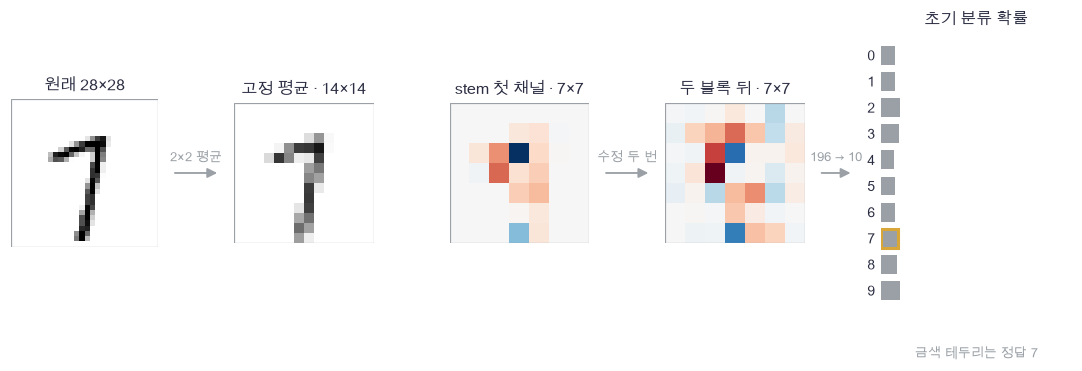

In [40]:
plot_classifier_flow(example_seven, classifier_image, classifier_stem[0, 0], classifier_h[0, 0], classifier_probabilities[0])

🔍 **그림 확인**

두 특징 지도는 네 채널 중 첫 채널만 보여 줍니다. 마지막 막대는 초기 가중치의 확률이라 정답 7이 가장 높을 필요가 없습니다. 앞의 두 경로 계산을 분류 손실과 연결하면 모든 가중치가 같은 CE를 줄이는 방향으로 갱신됩니다.

> **코드** · `reshape(N,1,14,2,14,2).mean(axis=(3,5))`는 2×2 화소씩 평균해 표본과 채널 축을 유지합니다. `f'{i}_W1'`은 블록 번호를 이름에 넣는 문자열입니다. `reversed(range(...))`는 뒤 블록부터 번호를 꺼냅니다. `array[rows, labels]`는 각 행에서 해당 정답 열 하나씩 고릅니다. `rng.permutation(N)`은 한 epoch에 모든 표본을 한 번씩 방문할 순서를 섞습니다.

In [41]:
# 쓰는 것: init_conv_block (3절 초기화)
def init_tiny_cnn(seed, channels=4, blocks=2):
    """14×14 입력을 받는 stem·동일채널 블록·선형 10분류기를 초기화합니다."""
    rng = np.random.default_rng(seed)
    params = {
        "stemW": rng.normal(size=(channels, 1, 3, 3)) / 3,
        "stemb": np.zeros(channels),
    }
    for i in range(blocks):
        block = init_conv_block(channels, channels, 1, rng)
        for name, value in block.items():
            params[f"{i}_{name}"] = value
    params["headW"] = rng.normal(size=(channels*7*7, 10)) / np.sqrt(channels*7*7)
    params["headb"] = np.zeros(10)
    return params

In [42]:
# 쓰는 것: conv_forward, conv_block_forward (3절)
def tiny_cnn_forward(x, params, residual, blocks=2):
    """stem→두 블록→flatten→10개 점수. x:(N,1,14,14) → logits:(N,10), cache."""
    pre, stem_cache = conv_forward(x, params["stemW"], params["stemb"], 2, 1)
    stem = np.tanh(pre)
    h = stem
    block_caches = []
    for i in range(blocks):
        block = {name: params[f"{i}_{name}"] for name in ["W1", "b1", "W2", "b2"]}
        h, block_cache = conv_block_forward(h, block, residual=residual, scale=0.5)
        block_caches.append((block, block_cache))
    flat = h.reshape(len(x), -1)
    logits = flat @ params["headW"] + params["headb"]
    return logits, (stem, stem_cache, block_caches, h.shape, flat)

In [43]:
# 쓰는 것: conv_backward, conv_block_backward (3절)
def tiny_cnn_backward(dlogits, cache, params):
    """분류 점수에서 입력까지 미분하고 모든 학습 파라미터 기울기를 반환합니다."""
    stem, stem_cache, block_caches, last_shape, flat = cache
    gradients = {"headW": flat.T @ dlogits, "headb": dlogits.sum(axis=0)}
    dh = (dlogits @ params["headW"].T).reshape(last_shape)
    for i in reversed(range(len(block_caches))):
        block, block_cache = block_caches[i]
        dh, block_gradients = conv_block_backward(dh, block_cache, block)
        for name, value in block_gradients.items():
            gradients[f"{i}_{name}"] = value
    dpre = dh * (1-stem**2)
    dx, gradients["stemW"], gradients["stemb"] = conv_backward(dpre, stem_cache)
    return dx, gradients

In [44]:
def softmax_cross_entropy(logits, labels):
    """표본 평균 CE와 점수 기울기. logits:(N,10), labels:(N,) → loss,dlogits."""
    shifted = logits - logits.max(axis=1, keepdims=True)
    log_normalizer = np.log(np.exp(shifted).sum(axis=1, keepdims=True))
    log_probabilities = shifted - log_normalizer
    rows = np.arange(len(labels))
    loss = -log_probabilities[rows, labels].mean()
    dlogits = np.exp(log_probabilities)
    dlogits[rows, labels] -= 1
    dlogits /= len(labels)
    return float(loss), dlogits

In [45]:
# 쓰는 것: classifier_x, classifier_logits (5절 개념 계산), init_tiny_cnn, tiny_cnn_forward (5절)
classifier_reference = init_tiny_cnn(1750)
classifier_actual, _ = tiny_cnn_forward(classifier_x, classifier_reference, True)
np.testing.assert_allclose(classifier_actual, classifier_logits)  # 검산: 전체 CNN이 그림 앞에서 직접 잇던 계산과 같습니다.
ce_zero, ce_gradient = softmax_cross_entropy(np.zeros((2,10)), np.array([0,9]))
np.testing.assert_allclose(ce_zero, np.log(10))  # 검산: 10개 클래스가 균등하면 CE=log(10)입니다.
np.testing.assert_allclose(ce_gradient.sum(axis=1), 0., atol=1e-15)  # 검산: 각 표본의 점수 기울기 합은 0입니다.
print('분류기 연결·손실 평균 축 검산 통과')

분류기 연결·손실 평균 축 검산 통과


In [46]:
# 쓰는 것: init_tiny_cnn, tiny_cnn_forward, tiny_cnn_backward, softmax_cross_entropy (5절)
def check_classifier_direction(residual):
    """전체 CNN의 모든 파라미터를 동시에 흔들어 임의 방향 미분을 대조합니다."""
    # 1. 각 원소 검산을 마친 블록들이 head·손실과 올바르게 연결되었는지 검사합니다.
    rng = np.random.default_rng(1751)
    x = rng.normal(0, .2, (2,1,14,14))
    labels = np.array([3,7])
    params = init_tiny_cnn(1752)
    logits, cache = tiny_cnn_forward(x, params, residual)
    _, dlogits = softmax_cross_entropy(logits, labels)
    dx, gradients = tiny_cnn_backward(dlogits, cache, params)
    directions = {name: rng.normal(size=value.shape) for name,value in params.items()}
    x_direction = rng.normal(size=x.shape)
    analytic = sum(np.sum(gradients[name]*directions[name]) for name in params) + np.sum(dx*x_direction)
    original = {name: value.copy() for name,value in params.items()}
    original_x = x.copy()
    values = []
    # 2. 같은 데이터·타깃을 사용하며 양쪽 방향에서 파라미터와 입력만 바꿉니다.
    for sign in [1., -1.]:
        for name in params:
            params[name][...] = original[name] + sign*1e-6*directions[name]
        x[...] = original_x + sign*1e-6*x_direction
        perturbed, _ = tiny_cnn_forward(x, params, residual)
        loss, _ = softmax_cross_entropy(perturbed, labels)
        values.append(loss)
    numeric = (values[0]-values[1])/2e-6
    np.testing.assert_allclose(analytic, numeric, rtol=2e-5, atol=1e-8)  # 검산: 모든 파라미터·입력 방향의 총 미분이 같습니다.
    return abs(analytic-numeric)

In [47]:
print('전체 plain CNN 방향 미분 오차:', check_classifier_direction(False))
print('전체 잔차 CNN 방향 미분 오차:', check_classifier_direction(True))

전체 plain CNN 방향 미분 오차: 1.0956457963118282e-11
전체 잔차 CNN 방향 미분 오차: 3.6711966799884976e-11


📎 **학습·검증·평가와 반복 단위**

실험 설정을 평가 전에 고정합니다. MNIST train 파일의 앞 1,200장을 학습, 다음 300장을 validation으로 쓰고, 별도 test 파일의 앞 600장을 마지막 평가에 씁니다. 자료를 섞어 분할하지 않아도 파일과 인덱스가 겹치지 않습니다. test 결과로 epoch나 seed를 고르지 않습니다. 숫자 종류는 10개 모두 포함합니다.

두 구조는 seed 171·172·173 각각 같은 초기 배열과 같은 미니배치 순서를 사용합니다. 최대 배치 64, 4 epoch, Adam 학습률 0.003입니다. seed 사이에는 초기 가중치와 순서를 새로 뽑지만 train/validation/test 자료는 고정합니다. 따라서 seed 간 표준편차는 **고정 자료에서의 초기화·학습 순서 변동**이며 새로운 데이터 분할의 불확실성을 재지 않습니다.

Adam은 $m_t=.9m_{t-1}+.1g_t$, $v_t=.999v_{t-1}+.001g_t^2$를 저장하고, $\hat m_t=m_t/(1-.9^t)$, $\hat v_t=v_t/(1-.999^t)$로 보정한 뒤 $\theta\leftarrow\theta-.003\hat m_t/(\sqrt{\hat v_t}+10^{-8})$로 갱신합니다. 각 배열마다 별도 상태를 갖습니다.

학습 CE와 stem 기울기 노름은 **각 배치의 갱신 직전 값**을 표본 수로 가중평균합니다. validation은 epoch 끝의 모델로 평가합니다. 서로 다른 시점의 수치이므로 train/validation 곡선의 차이를 그대로 일반화 격차로 부르지 않습니다.

> **용어** · **validation**은 학습 중 결과를 관찰하되 갱신에는 쓰지 않는 자료입니다. **test**는 고정 설정의 최종 성능을 보는 별도 자료입니다. **epoch**는 학습 표본 전체를 한 번 방문하는 단위입니다. **Adam**은 기울기의 이동 평균·제곱 평균으로 파라미터별 갱신 크기를 조절하는 optimizer입니다.

In [48]:
def adam_step(params, gradients, first, second, step, learning_rate=0.003):
    """같은 갱신 번호로 모든 파라미터의 Adam 편향을 보정합니다."""
    for name in params:
        first[name] = 0.9*first[name] + 0.1*gradients[name]
        second[name] = 0.999*second[name] + 0.001*gradients[name]**2
        corrected_first = first[name] / (1-0.9**step)
        corrected_second = second[name] / (1-0.999**step)
        params[name] -= learning_rate*corrected_first / (np.sqrt(corrected_second)+1e-8)

In [49]:
# 쓰는 것: tiny_cnn_forward, softmax_cross_entropy (5절)
def evaluate_cnn(x, labels, params, residual, batch_size=128):
    """고정 모델의 CE·정확도를 모든 표본에 대해 계산하며 마지막 작은 배치도 셉니다."""
    total_loss, correct = 0.0, 0
    for start in range(0, len(x), batch_size):
        stop = start + batch_size
        logits, _ = tiny_cnn_forward(x[start:stop], params, residual)
        loss, _ = softmax_cross_entropy(logits, labels[start:stop])
        total_loss += loss * len(logits)
        correct += np.sum(logits.argmax(axis=1) == labels[start:stop])
    return total_loss / len(x), correct / len(x)

In [50]:
# 쓰는 것: tiny_cnn_forward, tiny_cnn_backward, softmax_cross_entropy, evaluate_cnn, adam_step (5절)
def train_tiny_cnn(train_x, train_y, valid_x, valid_y, initial, residual, epochs=4, seed=170):
    """초깃값을 복사하고 고정 배치 순서로 학습합니다. 마지막 epoch의 모델과 기록을 반환합니다."""
    # 1. 같은 seed의 두 구조는 같은 가중치·배치 순서·Adam 설정으로 시작합니다.
    params = {name: value.copy() for name, value in initial.items()}
    first = {name: np.zeros_like(value) for name, value in params.items()}
    second = {name: np.zeros_like(value) for name, value in params.items()}
    order_rng = np.random.default_rng(seed)
    history, step = [], 0
    for epoch in range(1, epochs+1):
        order = order_rng.permutation(len(train_x))
        weighted_loss, weighted_norm = 0.0, 0.0
        # 2. 매 배치에서 두 경로의 미분을 합친 뒤 한 번 갱신합니다.
        for start in range(0, len(order), 64):
            indices = order[start:start+64]
            logits, cache = tiny_cnn_forward(train_x[indices], params, residual)
            loss, dlogits = softmax_cross_entropy(logits, train_y[indices])
            _, gradients = tiny_cnn_backward(dlogits, cache, params)
            weighted_loss += len(indices)*loss
            weighted_norm += len(indices)*np.linalg.norm(gradients["stemW"])
            step += 1
            adam_step(params, gradients, first, second, step)
        # 3. validation은 epoch가 끝난 한 모델로 측정합니다.
        valid_loss, valid_accuracy = evaluate_cnn(valid_x, valid_y, params, residual)
        history.append([epoch, weighted_loss/len(train_x), valid_loss, valid_accuracy, weighted_norm/len(train_x)])
    return params, np.asarray(history)

In [51]:
# 쓰는 것: load_mnist (준비 셀)
raw_train, all_train_labels, raw_test, all_test_labels = load_mnist(download=True, normalize=False)
mnist_train_x = raw_train[:1200].reshape(-1,1,14,2,14,2).mean(axis=(3,5))/255.
mnist_valid_x = raw_train[1200:1500].reshape(-1,1,14,2,14,2).mean(axis=(3,5))/255.
mnist_test_x = raw_test[:600].reshape(-1,1,14,2,14,2).mean(axis=(3,5))/255.
mnist_train_y = all_train_labels[:1200].copy()
mnist_valid_y = all_train_labels[1200:1500].copy()
mnist_test_y = all_test_labels[:600].copy()
del raw_train, raw_test
TRAIN_SEEDS = [171, 172, 173]
EPOCHS = 4
print('train / validation / test:', len(mnist_train_x), len(mnist_valid_x), len(mnist_test_x))
print('각 실행의 최대 배치64, epoch4, 갱신 수:', EPOCHS*int(np.ceil(len(mnist_train_x)/64)))

train / validation / test: 1200 300 600
각 실행의 최대 배치64, epoch4, 갱신 수: 76


In [52]:
# 쓰는 것: init_tiny_cnn, adam_step (5절)
count_reference = init_tiny_cnn(TRAIN_SEEDS[0])
parameter_count = sum(value.size for value in count_reference.values())
assert parameter_count == 2602, "stem40+블록2×296+head1970=2602여야 합니다"
print('동일한 학습 파라미터 수:', parameter_count)
adam_probe = {'w': np.array([1., -2.])}
adam_first, adam_second = {'w': np.zeros(2)}, {'w': np.zeros(2)}
adam_step(adam_probe, {'w': np.array([2., -4.])}, adam_first, adam_second, 1, learning_rate=.01)
np.testing.assert_allclose(adam_probe['w'], [.99, -1.99], atol=1e-9)  # 검산: 첫 Adam 갱신은 기울기 부호 반대로 약 .01입니다.
print('초기 상태에서 Adam 편향 보정 검산 통과')

동일한 학습 파라미터 수: 2602
초기 상태에서 Adam 편향 보정 검산 통과


In [53]:
# 쓰는 것: train_tiny_cnn, init_tiny_cnn (5절), mnist_train_x, mnist_train_y, mnist_valid_x, mnist_valid_y, TRAIN_SEEDS, EPOCHS (자료 셀)
experiment_start = perf_counter()
mode_names = ['plain', '잔차']
histories = np.empty((2, len(TRAIN_SEEDS), EPOCHS, 5))
trained_models = {}
for r, seed in enumerate(TRAIN_SEEDS):
    initial = init_tiny_cnn(seed)
    for mode, skip in enumerate([False, True]):
        model, history = train_tiny_cnn(mnist_train_x, mnist_train_y, mnist_valid_x, mnist_valid_y,
                                        initial, skip, epochs=EPOCHS, seed=seed+1000)
        histories[mode, r] = history
        trained_models[(mode, seed)] = model
        print(mode_names[mode], 'seed', seed, '마지막 validation 정확도', round(history[-1,3], 4))
history_means = histories.mean(axis=1)
history_sds = histories.std(axis=1, ddof=1)

plain seed 171 마지막 validation 정확도 0.7467


잔차 seed 171 마지막 validation 정확도 0.8267


plain seed 172 마지막 validation 정확도 0.79


잔차 seed 172 마지막 validation 정확도 0.8133


plain seed 173 마지막 validation 정확도 0.74


잔차 seed 173 마지막 validation 정확도 0.8067


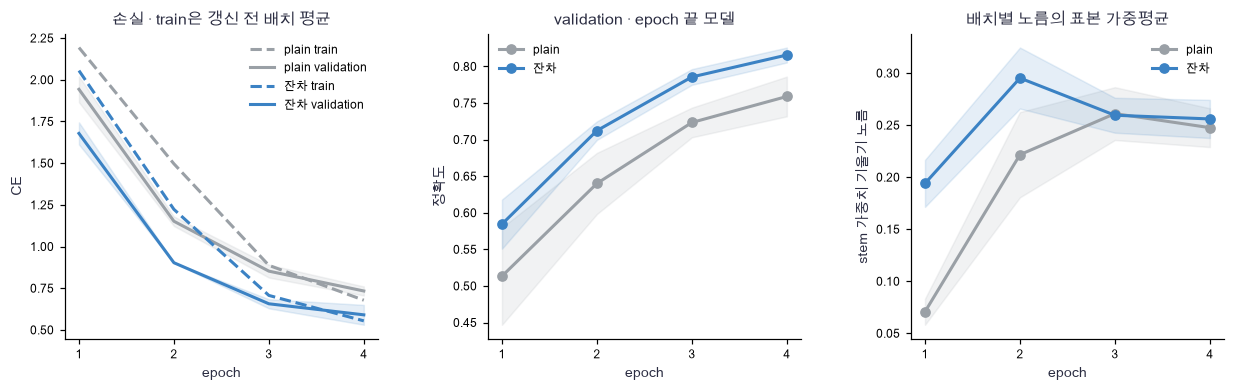

In [54]:
plot_training_comparison(history_means, history_sds, mode_names)

🔍 **학습 곡선 확인**

실선은 세 seed의 평균, 옅은 띠는 seed 간 SD입니다. 마지막 판은 stem 가중치 기울기 노름이며 입력 기울기나 모델 전체 노름이 아닙니다. 노름이 더 크다고 좋은 학습이라고 단정하지 않고 CE·정확도의 변화와 함께 읽습니다. 곡선이 유한한지 확인한 뒤, 설정을 바꾸지 않은 채 test를 한 번 평가합니다.

In [55]:
# 쓰는 것: evaluate_cnn, trained_models, mode_names, TRAIN_SEEDS, parameter_count, histories (5절), mnist_test_x, mnist_test_y (자료 셀)
test_results = np.empty((2, len(TRAIN_SEEDS), 2))
for mode, skip in enumerate([False, True]):
    for r, seed in enumerate(TRAIN_SEEDS):
        model = trained_models[(mode, seed)]
        test_results[mode, r] = evaluate_cnn(mnist_test_x, mnist_test_y, model, skip)
        assert sum(value.size for value in model.values()) == parameter_count, "두 구조의 학습 파라미터 수는 같아야 합니다"
for mode, name in enumerate(mode_names):
    mean_metrics = test_results[mode].mean(axis=0)
    sd_metrics = test_results[mode].std(axis=0, ddof=1)
    print(f'{name}: test CE {mean_metrics[0]:.4f} ± {sd_metrics[0]:.4f}, 정확도 {mean_metrics[1]:.3f} ± {sd_metrics[1]:.3f} (seed SD)')
paired_accuracy = test_results[1,:,1]-test_results[0,:,1]
print('같은 seed의 잔차 − plain 정확도 차이:', paired_accuracy)
assert np.all(np.isfinite(histories)), "학습·검증 기록이 모두 유한해야 합니다"
assert np.all(np.isfinite(test_results)), "최종 평가 수치가 모두 유한해야 합니다"
print('공통 파라미터·표본 예산과 유한 수치 확인 · 우열은 관측값으로 읽습니다.')

plain: test CE 0.7702 ± 0.0689, 정확도 0.754 ± 0.038 (seed SD)
잔차: test CE 0.6702 ± 0.0104, 정확도 0.771 ± 0.024 (seed SD)
같은 seed의 잔차 − plain 정확도 차이: [-0.00666667  0.03833333  0.01833333]
공통 파라미터·표본 예산과 유한 수치 확인 · 우열은 관측값으로 읽습니다.


In [56]:
# 쓰는 것: mnist_test_x, mnist_test_y (자료 셀), trained_models, TRAIN_SEEDS, tiny_cnn_forward (5절)
display_seed = TRAIN_SEEDS[0]
display_logits, _ = tiny_cnn_forward(mnist_test_x[:10], trained_models[(1,display_seed)], True)
display_predictions = display_logits.argmax(axis=1)

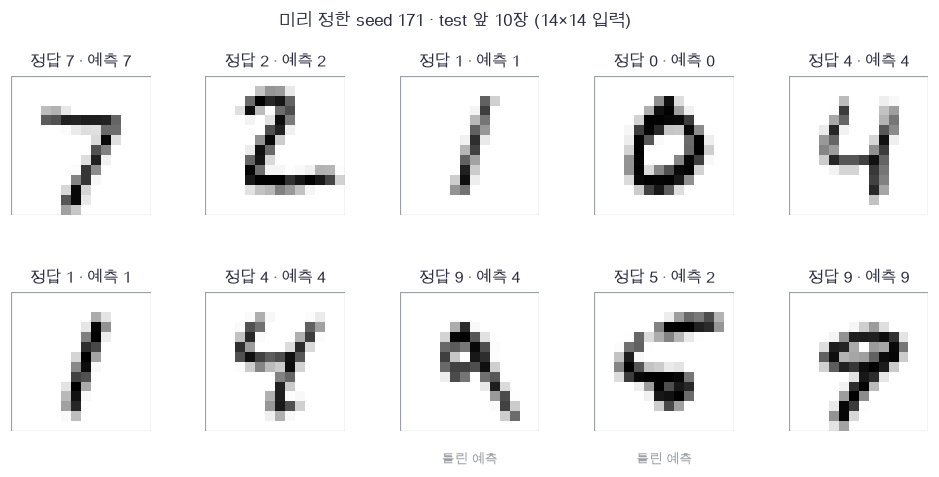

In [57]:
plot_test_predictions(mnist_test_x[:10, 0], mnist_test_y[:10], display_predictions, display_seed)

🔍 **결과의 범위**

그림은 미리 정한 **첫 seed 잔차 모델·test 앞 10장**입니다. 잘 맞힌 그림만 고르지 않았으며 전체 지표는 같은 600장 모두에서 계산했습니다. 같은 seed의 차이를 보는 이유는 초기화·순서 조건을 맞추기 위해서입니다. 세 차이의 평균이 양수여도 모든 초기화·깊이·분할에서 잔차가 이긴다는 뜻은 아닙니다.

이 실험은 정규화를 생략하고 같은 배율을 준 축소 tanh CNN입니다. 원 논문 구조와의 차이, 줄인 해상도, 적은 train, 고정 분할을 함께 기록해야 합니다. 실제 모델을 확장할 때는 [16](16_normalization.ipynb)의 정규화 위치와 train/eval, [15](../02_연결/15_experiments_evaluation.ipynb)의 설정 선택 절차를 먼저 적용합니다. 스킵만 추가하면 언제나 정확도가 오른다는 주장은 여기서 검산하지 않았습니다.

### ✏️ 연습 5 · 크기가 다른 배치의 정확도 합치기

배치별 맞힌 개수 `correct`와 표본 수 `counts`에서 전체 정확도 한 줄을 채우세요. 배치 정확도의 단순 평균을 내지 않습니다.

In [58]:
def exercise_total_accuracy(correct, counts):
    """같은 표본 분모로 전체 정확도를 계산합니다."""
    raise NotImplementedError
    return accuracy

In [59]:
def check_total_accuracy(candidate):
    """큰 배치 2/3, 작은 배치 1/1의 전체 정확도는 3/4입니다."""
    value = candidate(np.array([2,1]), np.array([3,1]))
    np.testing.assert_allclose(value, .75)  # 검산: (2+1)/(3+1)=.75입니다.
run_check(check_total_accuracy, exercise_total_accuracy)

☐ exercise_total_accuracy: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
accuracy = np.sum(correct) / np.sum(counts)
```

</details>

## ✏️ 전체 연결 연습 A–D

학습을 다시 돌리지 않고 핵심 항등식과 shape를 확인합니다. 먼저 손으로 답을 적고 빈 한두 줄을 채워 보세요.

### ✏️ 연습 A · 투영 경로의 미분

행벡터 배치에서 `skip = x @ projection`이고 출력 상류 기울기가 `g`입니다. `projection:(Din,Dout)`에 대해 스킵 입력 기울기 한 줄을 채우세요.

In [60]:
def exercise_projection_backward(g, projection):
    """투영 스킵의 기울기는 항등 기울기와 다릅니다."""
    raise NotImplementedError
    return dx_skip

In [61]:
def check_projection_backward(candidate):
    """한 입력을 두 채널로 보내는 2·-1 가중치의 기여를 합칩니다."""
    actual = candidate(np.array([[3.,4.]]), np.array([[2.,-1.]]))
    np.testing.assert_allclose(actual, [[2.]])  # 검산: 3×2+4×(-1)=2입니다.
run_check(check_projection_backward, exercise_projection_backward)

☐ exercise_projection_backward: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dx_skip = g @ projection.T
```

</details>

### ✏️ 연습 B · zero-residual과 post-ReLU

수정량이 0인 입력 `x`에서 합 뒤 활성화가 없는 출력과 ReLU를 붙인 출력을 두 줄로 채우세요.

In [62]:
def exercise_zero_branch(x):
    """수정량 0만으로 두 구조를 같은 함수라고 할 수 없는 이유를 확인합니다."""
    raise NotImplementedError
    return identity, post_relu

In [63]:
def check_zero_branch(candidate):
    """음수 한 좌표가 두 구조를 구별합니다."""
    identity, post_relu = candidate(np.array([-2.,3.]))
    np.testing.assert_array_equal(identity, [-2.,3.])  # 검산: 항등 경로는 음수도 유지합니다.
    np.testing.assert_array_equal(post_relu, [0.,3.])  # 검산: ReLU는 음수 좌표를 지웁니다.
run_check(check_zero_branch, exercise_zero_branch)

☐ exercise_zero_branch: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
identity = x.copy()
post_relu = np.maximum(x, 0)
```

</details>

### ✏️ 연습 C · 분류 기울기의 평균 축

`probabilities:(N,K)`와 정답 번호 `labels:(N,)`가 주어집니다. 준비된 독립 복사본 `gradient`에서 정답 항을 빼고 표본 수로 나누는 두 줄을 채우세요.

In [64]:
def exercise_ce_gradient(probabilities, labels):
    """softmax CE의 p-onehot을 표본 평균으로 바꿉니다."""
    gradient = probabilities.copy()
    rows = np.arange(len(labels))
    raise NotImplementedError
    return gradient

In [65]:
def check_ce_gradient(candidate):
    """두 표본·두 클래스의 손계산 평균 기울기를 확인합니다."""
    actual = candidate(np.array([[.25,.75],[.6,.4]]), np.array([1,0]))
    np.testing.assert_allclose(actual, [[.125,-.125],[-.2,.2]])  # 검산: 각 행에서 정답을 뺀 뒤 N=2로 나눕니다.
run_check(check_ce_gradient, exercise_ce_gradient)

☐ exercise_ce_gradient: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
gradient[rows, labels] -= 1
gradient /= len(labels)
```

</details>

### ✏️ 연습 D · 같은 seed끼리 차이 재기

`plain_accuracy`와 `residual_accuracy`는 같은 seed 순서입니다. seed별 차이와 그 평균을 두 줄로 채우세요.

In [66]:
def exercise_paired_difference(plain_accuracy, residual_accuracy):
    """독립 모델 수를 유지한 채 같은 조건의 차이를 계산합니다."""
    raise NotImplementedError
    return difference, average

In [67]:
def check_paired_difference(candidate):
    """한 seed에서는 좋아지고 다른 seed에서는 나빠지는 경우입니다."""
    difference, average = candidate(np.array([.7,.8]), np.array([.8,.75]))
    np.testing.assert_allclose(difference, [.1,-.05])  # 검산: 각 seed의 잔차−plain을 유지합니다.
    np.testing.assert_allclose(average, .025)  # 검산: 두 차이의 평균은 .025입니다.
run_check(check_paired_difference, exercise_paired_difference)

☐ exercise_paired_difference: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
difference = residual_accuracy - plain_accuracy
average = np.mean(difference)
```

</details>

## ✏️ 다음 단계 준비도

**설명 확인:** 수정 경로와 스킵 경로는 각각 무엇을 하나요? $F(x)=0$이어도 post-ReLU가 항등 함수가 아닌 이유는 무엇인가요? 이 노트북의 작은 CNN과 원래 ResNet-18의 차이를 말할 수 있나요?

**수식 확인:** $y=P(x)+\alpha F(x)$에서 입력·투영 커널·주경로 커널의 미분을 나눌 수 있나요? $F'(x)=-1,0,1$일 때 여러 잔차 블록의 미분이 어떻게 되는지 손으로 설명할 수 있나요?

**구현 확인:** 합성곱 창을 행으로 펴는 축과 뒤에서 겹치는 화소 기여를 더하는 위치를 찾을 수 있나요? optimizer에 전달하기 전에 두 경로의 입력 기울기가 합쳐졌는지 확인할 수 있나요? 마지막 작은 배치까지 같은 분모로 평가하나요?

**변형 검산:** 입력 높이를 홀수로 바꾸거나 채널 수를 늘렸을 때 투영과 주경로 shape를 검산할 수 있나요? 배율 $\alpha$를 바꿀 때 forward와 backward의 어느 줄이 함께 바뀌나요? 깊이·정규화·초기화 중 하나를 바꾸는 실험에서 나머지 조건과 seed 반복을 어떻게 고정하겠습니까?

다음에는 [16](16_normalization.ipynb)의 정규화 층을 어디에 넣을지, [18](18_unet.ipynb)의 공간 특징 연결은 왜 덧셈 대신 이어붙이기도 하는지를 비교합니다. 새 설정을 선택할 때는 train/validation을 사용하고 test를 다시 선택 도구로 쓰지 않습니다.

In [68]:
# 쓰는 것: experiment_start (5절 실험 시작)
print(f'세 seed·두 구조의 학습과 평가 경과 시간: {perf_counter()-experiment_start:.2f}초')

세 seed·두 구조의 학습과 평가 경과 시간: 2.33초
